# Task 3: finding the mislabelled training images

Every training image gets a score: higher means its noisy label is more likely wrong.

Main signal (decided before looking at any clean-label check): **5-fold cross-validated confidence**. The 45,000 training images are split into 5 stratified folds. For each fold a ResNet-18 is trained on the other four folds with the noisy labels (same setup, 60 epochs) and predicts the held-out fold after every epoch. The held-out probabilities are averaged from epoch 10 up to that fold's best epoch on noisy validation accuracy, so every image is judged by models that never saw its label, the average smooths out single-epoch noise, and the late epochs where the network has started fitting wrong labels are left out. Score = 1 − averaged probability of the given noisy label.

Other signals, compared afterwards:
* **early loss**: mean cross-entropy of the noisy label over epochs 1 to the Task 2 early-stopping epoch (picked on noisy validation accuracy), taken from the Task 1 noisy run (no extra training);
* **CV last epoch**: the same as the main signal but using only the final epoch;
* **CV disagreement**: 1 if the averaged out-of-fold prediction differs from the noisy label;
* **combined**: mean of the ranks of CV confidence and early loss.

All windows are set from noisy validation accuracy, never from the clean-label curves. Clean labels are used only for the final check (AUROC and precision@k, k = number of wrong labels). 5 training runs in total, within the Task 3 budget. Runtime on an A100: about 25 minutes; each fold is saved to `work/` as it finishes.

In [1]:
# project folder: MyDrive/cv_bootcamp (data/, model.py, check_format.py, results_template.json, code/cvlib.py).
# If it is not there yet, it is unpacked from MyDrive/cv_bootcamp.zip, or from a zip picked in the file dialog.
import sys, zipfile
from pathlib import Path

try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/cv_bootcamp")
except ImportError:                      # running outside Colab
    files = None
    ROOT = Path.cwd() / "cv_bootcamp"

if not (ROOT / "data" / "labels.csv").exists():
    zips = [z for z in [ROOT.parent / "cv_bootcamp.zip"] if z.exists()] + list(Path.cwd().glob("cv_bootcamp*.zip"))
    if not zips:
        zips = [Path(name) for name in files.upload()]
    zipfile.ZipFile(zips[0]).extractall(ROOT.parent)
    print("unpacked", zips[0].name, "into", ROOT.parent)

assert (ROOT / "data" / "labels.csv").exists() and (ROOT / "code" / "cvlib.py").exists()
sys.path.insert(0, str(ROOT / "code"))
print("project folder:", ROOT)

Mounted at /content/drive
project folder: /content/drive/MyDrive/cv_bootcamp


In [2]:
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import cvlib as cv

WORK = ROOT / "work"
PRED = ROOT / "predictions"
WORK.mkdir(exist_ok=True)
PRED.mkdir(exist_ok=True)

print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
data = cv.Data(ROOT)
print("train", len(data.train_idx), " val", len(data.val_idx), " test", len(data.x_test))
print("classes:", data.classes)

device: NVIDIA A100-SXM4-80GB
train 45000  val 5000  test 10000
classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

lab = data.labels
tr, va = data.train_idx, data.val_idx
noisy, clean = lab["noisy_label"].to_numpy(), lab["clean_label"].to_numpy()
y_tr = noisy[tr]
res = cv.load_results(WORK)
early_stop = res["task2"]["early_stop_epoch"]          # chosen on noisy validation accuracy in Task 2
print("early-stopping epoch from Task 2:", early_stop)

K, AVG_FROM = 5, 10
folds = list(StratifiedKFold(n_splits=K, shuffle=True, random_state=cv.SEED).split(tr, y_tr))
print([len(h) for _, h in folds])

early-stopping epoch from Task 2: 38
[9000, 9000, 9000, 9000, 9000]


## Cross-validated training (5 runs)

In [4]:
def run_fold(k, fit, hold, labels, prefix):
    path = WORK / f"{prefix}_fold{k}.npz"
    if path.exists():
        return dict(np.load(path))
    held = []
    rec = cv.Recorder(data, labels[va])

    def on_epoch(ep, net):
        held.append(cv.predict(net, data.x[tr[hold]]).astype(np.float16))
        return rec(ep, net)

    cv.train(data, tr[fit], labels[tr][fit], seed=cv.SEED + k, on_epoch=on_epoch, tag=f"{prefix} fold {k}")
    np.savez_compressed(path, hold=hold, probs=np.stack(held), val_acc=np.array(rec.val_acc))
    return dict(np.load(path))

oof_avg = np.zeros((len(tr), 10), np.float32)
oof_last = np.zeros((len(tr), 10), np.float32)
for k, (fit, hold) in enumerate(folds):
    f = run_fold(k, fit, hold, noisy, "t3")
    best = int(f["val_acc"].argmax()) + 1                      # this fold's best epoch on noisy val accuracy
    lo = min(AVG_FROM, best)
    oof_avg[f["hold"]] = f["probs"][lo - 1:best].astype(np.float32).mean(0)
    oof_last[f["hold"]] = f["probs"][-1].astype(np.float32)
    print(f"fold {k}: best noisy val acc {f['val_acc'].max():.4f} at epoch {best}, averaging epochs {lo}-{best}")

t3 fold 0 epoch  1  loss 2.2903  val_acc 0.2582  (18s)
t3 fold 0 epoch  5  loss 1.7974  val_acc 0.3706  (31s)
t3 fold 0 epoch 10  loss 1.6286  val_acc 0.4476  (47s)
t3 fold 0 epoch 15  loss 1.5354  val_acc 0.4738  (64s)
t3 fold 0 epoch 20  loss 1.4887  val_acc 0.4692  (81s)
t3 fold 0 epoch 25  loss 1.4467  val_acc 0.4916  (97s)
t3 fold 0 epoch 30  loss 1.4025  val_acc 0.5214  (113s)
t3 fold 0 epoch 35  loss 1.3489  val_acc 0.5410  (130s)
t3 fold 0 epoch 40  loss 1.2763  val_acc 0.5214  (146s)
t3 fold 0 epoch 45  loss 1.1514  val_acc 0.5348  (163s)
t3 fold 0 epoch 50  loss 0.9286  val_acc 0.5202  (179s)
t3 fold 0 epoch 55  loss 0.5927  val_acc 0.5026  (196s)
t3 fold 0 epoch 60  loss 0.4014  val_acc 0.4846  (212s)
fold 0: best noisy val acc 0.5420 at epoch 32, averaging epochs 10-32
t3 fold 1 epoch  1  loss 2.1930  val_acc 0.2766  (3s)
t3 fold 1 epoch  5  loss 1.7637  val_acc 0.3686  (17s)
t3 fold 1 epoch 10  loss 1.6185  val_acc 0.4428  (33s)
t3 fold 1 epoch 15  loss 1.5245  val_acc 0.4

## Scores

In [5]:
pos = np.arange(len(tr))

noisy_run = np.load(WORK / "t1_noisy_ce.npz")
tp = noisy_run["train_probs"][:early_stop].astype(np.float32)        # epochs 1..early_stop of the Task 1 noisy run
early_loss = -np.log(np.clip(tp[:, pos, y_tr], 1e-7, 1)).mean(0)

def ranks(s):
    return pd.Series(s).rank(pct=True).to_numpy()

signals = {
    "cv_confidence (submitted)": 1 - oof_avg[pos, y_tr],
    "cv_last_epoch": 1 - oof_last[pos, y_tr],
    "early_loss": early_loss,
    "cv_disagreement": (oof_avg.argmax(1) != y_tr).astype(float),
    "combined_rank": (ranks(1 - oof_avg[pos, y_tr]) + ranks(early_loss)) / 2,
}
score = signals["cv_confidence (submitted)"]

pd.DataFrame({"index": tr, "score": np.round(score, 6)}).to_csv(PRED / "t3_noise_scores.csv", index=False)

est_noise = float((oof_avg.argmax(1) != y_tr).mean())      # noise-rate estimate without clean labels, used in Task 4
np.savez_compressed(WORK / "t3_oof.npz", oof_avg=oof_avg, score=score, est_noise_rate=est_noise)
print(f"estimated noise rate from CV disagreement (no clean labels): {est_noise:.4f}")
cv.update_results(WORK, task3={"method": "5-fold cross-validated confidence: 1 - out-of-fold probability of the noisy label, averaged from epoch 10 to each fold's best noisy-val epoch"})

estimated noise rate from CV disagreement (no clean labels): 0.4398


{'task1': {'noise_rate': 0.4024,
  'val_acc_noisy_labels__clean_ref_model': 0.5918,
  'val_acc_noisy_labels__noisy_ce_model': 0.4924},
 'seed': 42,
 'training_setup': {'optimizer': 'SGD (momentum 0.9, nesterov, weight decay 5e-4)',
  'learning_rate_schedule': 'cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup',
  'batch_size': 128,
  'epochs': 60,
  'augmentation': 'random crop 32x32 with 4-pixel zero padding, random horizontal flip'},
 'extra': {'clean_ref_val_acc_clean': 0.9446,
  'noisy_ce_val_acc_clean_final': 0.6844,
  'noisy_ce_val_acc_clean_early_stop': 0.779,
  'clean_val_peak_epoch': 43},
 'task2': {'memorization_start_epoch': 31,
  'early_stop_epoch': 38,
  'val_acc_noisy_labels_at_early_stop': 0.556},
 'task3': {'method': "5-fold cross-validated confidence: 1 - out-of-fold probability of the noisy label, averaged from epoch 10 to each fold's best noisy-val epoch"}}

## Check against the clean labels (measurement only)

In [6]:
wrong = noisy[tr] != clean[tr]
k_true = int(wrong.sum())

def prec_at_k(s):
    top = np.argsort(-s, kind="stable")[:k_true]
    return wrong[top].mean()

check = pd.DataFrame({name: {"AUROC": roc_auc_score(wrong, s), "precision@k": prec_at_k(s)}
                      for name, s in signals.items()}).T.round(4)
print(f"k = {k_true} wrongly labelled training images")
display(check)
cv.update_results(WORK, extra={"t3_auroc": round(float(check.iloc[0]["AUROC"]), 4),
                               "t3_precision_at_k": round(float(check.iloc[0]["precision@k"]), 4),
                               "t3_check": check.to_dict("index")})

k = 18109 wrongly labelled training images


,AUROC,precision@k
cv_confidence (submitted),0.9418,0.8307
cv_last_epoch,0.8774,0.7637
early_loss,0.9371,0.8172
cv_disagreement,0.8834,0.8222
combined_rank,0.9417,0.8270


{'task1': {'noise_rate': 0.4024,
  'val_acc_noisy_labels__clean_ref_model': 0.5918,
  'val_acc_noisy_labels__noisy_ce_model': 0.4924},
 'seed': 42,
 'training_setup': {'optimizer': 'SGD (momentum 0.9, nesterov, weight decay 5e-4)',
  'learning_rate_schedule': 'cosine annealing per step, 0.1 to 0 over 60 epochs, no warmup',
  'batch_size': 128,
  'epochs': 60,
  'augmentation': 'random crop 32x32 with 4-pixel zero padding, random horizontal flip'},
 'extra': {'clean_ref_val_acc_clean': 0.9446,
  'noisy_ce_val_acc_clean_final': 0.6844,
  'noisy_ce_val_acc_clean_early_stop': 0.779,
  'clean_val_peak_epoch': 43,
  't3_auroc': 0.9418,
  't3_precision_at_k': 0.8307,
  't3_check': {'cv_confidence (submitted)': {'AUROC': 0.9418,
    'precision@k': 0.8307},
   'cv_last_epoch': {'AUROC': 0.8774, 'precision@k': 0.7637},
   'early_loss': {'AUROC': 0.9371, 'precision@k': 0.8172},
   'cv_disagreement': {'AUROC': 0.8834, 'precision@k': 0.8222},
   'combined_rank': {'AUROC': 0.9417, 'precision@k': 0.8

In [7]:
# which kinds of wrong labels the score catches: share of each (true -> given) pair that lands in the top k
top = np.zeros(len(tr), bool)
top[np.argsort(-score, kind="stable")[:k_true]] = True
pairs = pd.DataFrame({"true": clean[tr], "given": y_tr, "caught": top})[wrong]
by_pair = (pairs.groupby(["true", "given"]).caught.agg(["size", "mean"])
           .sort_values("size", ascending=False).head(12).reset_index())
by_pair["pair"] = [f"{data.classes[a]} -> {data.classes[b]}" for a, b in zip(by_pair.true, by_pair.given)]
by_pair = by_pair[["pair", "size", "mean"]].rename(columns={"size": "wrong labels", "mean": "share caught in top k"})
display(by_pair.round(3))

# false alarms: correctly labelled images inside the top k, by class
fa = pd.Series(y_tr[top & ~wrong]).value_counts().rename(index=dict(enumerate(data.classes)))
print("correct labels flagged in the top k, by class:")
print(fa.to_string())

,pair,wrong labels,share caught in top k
0,truck -> automobile,1247,0.358
1,automobile -> truck,1126,0.646
2,cat -> dog,924,0.551
3,dog -> cat,834,0.606
4,deer -> horse,683,0.630
5,deer -> dog,491,0.921
6,airplane -> ship,379,0.670
7,frog -> bird,373,0.912
8,ship -> airplane,369,0.900
9,cat -> bird,354,0.881


correct labels flagged in the top k, by class:
cat           534
deer          502
bird          462
dog           361
frog          320
airplane      287
horse         266
truck         145
ship          125
automobile     64


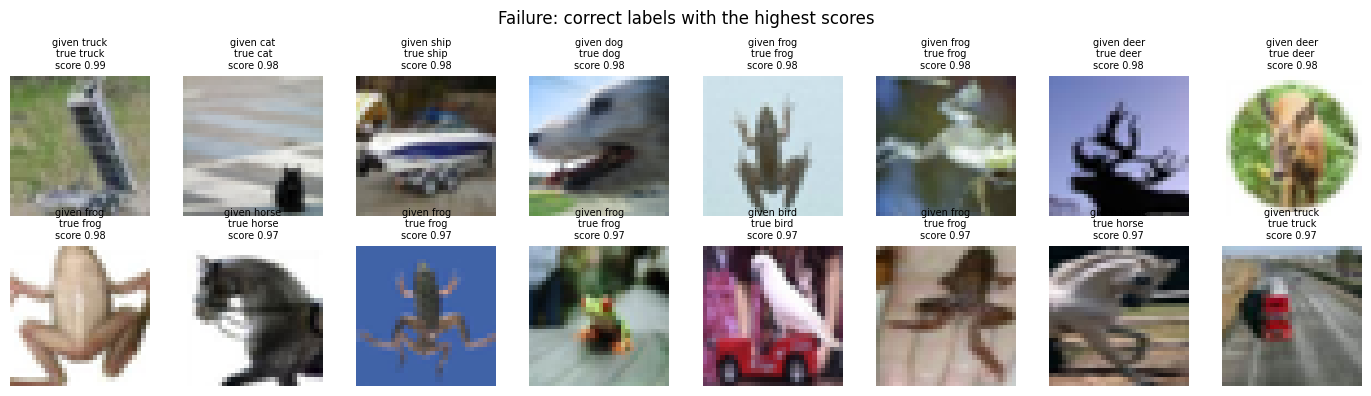

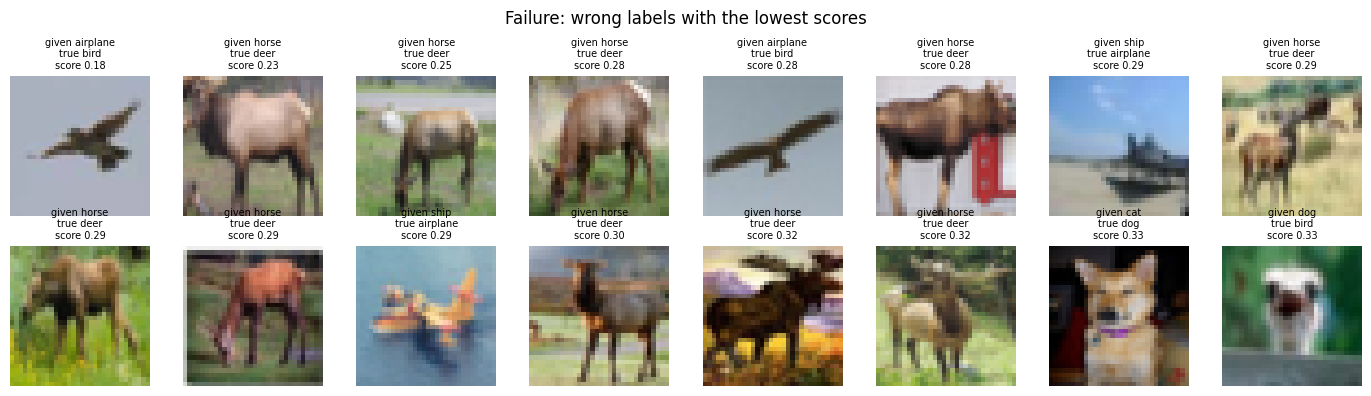

In [8]:
def show(positions, title, path):
    imgs = data.x[tr[positions]].permute(0, 2, 3, 1).cpu().numpy()
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    for a, i, p in zip(axes.flat, imgs, positions):
        a.imshow(i); a.axis("off")
        a.set_title(f"given {data.classes[y_tr[p]]}\ntrue {data.classes[clean[tr][p]]}\nscore {score[p]:.2f}", fontsize=7)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

order = np.argsort(-score, kind="stable")
show(order[~wrong[order]][:16], "Failure: correct labels with the highest scores", WORK / "t3_false_alarms.png")
low_first = np.argsort(score, kind="stable")
show(low_first[wrong[low_first]][:16], "Failure: wrong labels with the lowest scores", WORK / "t3_missed.png")